In [ ]:
!pip install statsmodels
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_pacf, plot_acf
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings('ignore')

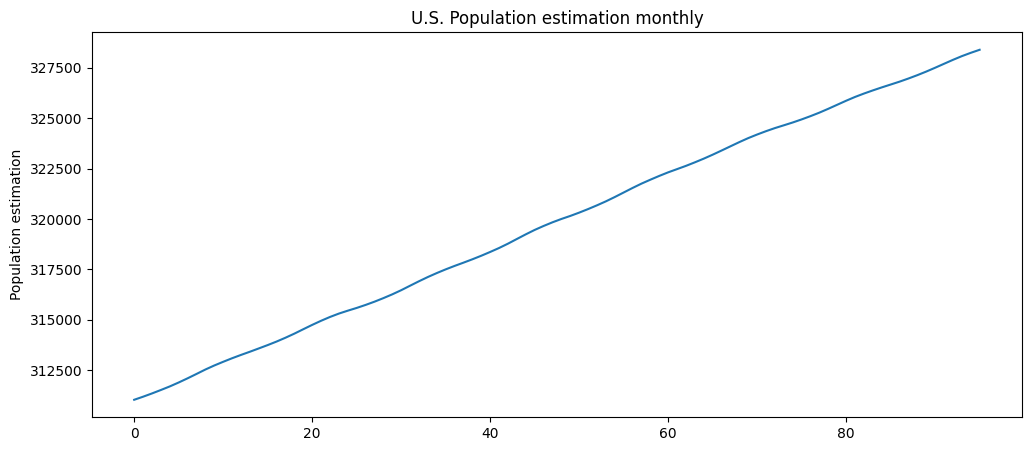

In [ ]:
df=pd.read_csv("/content/uspopulation.csv")
df.index.fr="MS"
df["PopEst"].plot(figsize=(12,5),title="U.S. Population estimation monthly")
plt.ylabel("Population estimation")
plt.show()

In [ ]:
train=df.iloc[:84]
test=df.iloc[84:]

<Figure size 800x400 with 0 Axes>

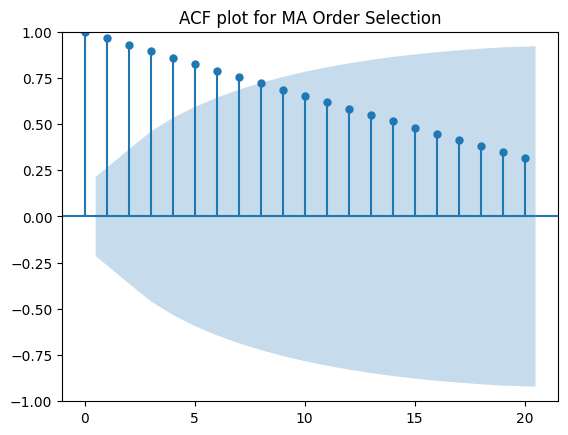

In [ ]:
plt.figure(figsize=(8,4))
plot_acf(train["PopEst"],lags=20)
plt.title("ACF plot for MA Order Selection")
plt.show()

In [ ]:
ma1 = ARIMA(train["PopEst"], order=(0,1,0))
results_ma1 = ma1.fit()
pred_ma1 = results_ma1.predict(start=len(train), end=len(train) + len(test) - 1, dynamic=False)

ma2 = ARIMA(train["PopEst"], order=(0,2,0))
results_ma2 = ma2.fit()
pred_ma2 = results_ma2.predict(start=len(train), end=len(train) + len(test) - 1, dynamic=False)

ma6 = ARIMA(train["PopEst"], order=(0,6,0))
results_ma6 = ma6.fit()
pred_ma6 = results_ma6.predict(start=len(train), end=len(train) + len(test) - 1, dynamic=False)

In [ ]:
error_ma1 = mean_squared_error(test["PopEst"], pred_ma1)
error_ma2 = mean_squared_error(test["PopEst"], pred_ma2)
error_ma6 = mean_squared_error(test["PopEst"], pred_ma6)

print(f"MSE for ARIMA(0,1,0): {error_ma1:.2f}")
print(f"MSE for ARIMA(0,2,0): {error_ma2:.2f}")
print(f"MSE for ARIMA(0,6,0): {error_ma6:.2f}")

MSE for ARIMA(0,1,0): 1483818.83
MSE for ARIMA(0,2,0): 6940.83
MSE for ARIMA(0,6,0): 1281534498.76


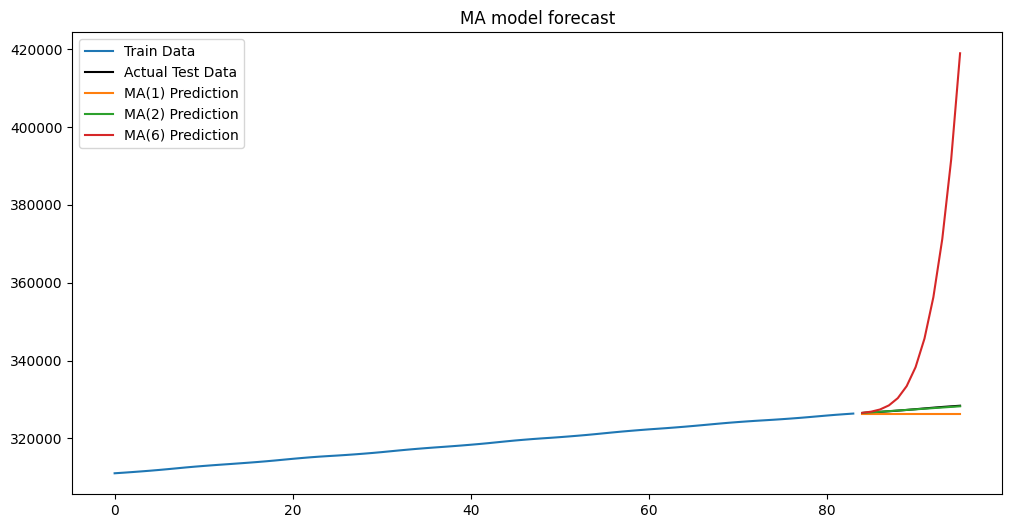

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(train["PopEst"].index, train["PopEst"], label='Train Data')
plt.plot(test["PopEst"].index, test["PopEst"], label='Actual Test Data',color='black')
plt.plot(test.index,pred_ma1,label="MA(1) Prediction")
plt.plot(test.index,pred_ma2,label="MA(2) Prediction")
plt.plot(test.index,pred_ma6,label="MA(6) Prediction")
plt.legend()

plt.title('MA model forecast')

plt.show()

In [ ]:
for label,pred in zip(["MA(1)","MA(2)","MA(6)"],[pred_ma1,pred_ma2,pred_ma6]):
  error=mean_squared_error(test["PopEst"],pred)
  print(f"{label}MSE:{error:.2f}")

MA(1)MSE:1483818.83
MA(2)MSE:6940.83
MA(6)MSE:1281534498.76


In [ ]:
final_ma = ARIMA(df["PopEst"], order=(0,2,0))
results_final_ma = final_ma.fit()
forecast = results_final_ma.predict(start=len(df), end=len(df) + 11, dynamic=False)

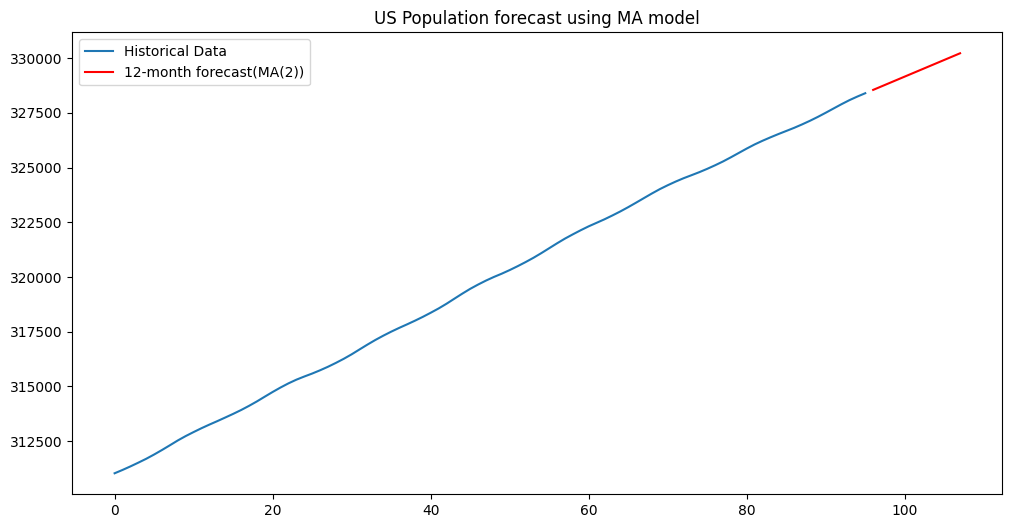

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(df.index,df["PopEst"],label="Historical Data")
plt.plot(forecast.index, forecast,label="12-month forecast(MA(2))",color="red")
plt.legend()
plt.title("US Population forecast using MA model")
plt.show()